# 02 · Exploratory Data Analysis: Telco Customer Churn

**Input:** `data/processed/churn.parquet`, the cleaned output of `src/ingest.py` (7,043 customers × 21 columns).

**Questions this notebook answers:**
1. How imbalanced is the target?
2. Which customer segments churn the most?
3. How do tenure and charges differ between churners and stayers?
4. How does churn risk change over the customer lifetime?
5. Which numeric features are strongly correlated?

EDA only describes **associations**, not causes. Findings here guide feature engineering and modeling in `src/train.py`.

In [7]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent          # notebooks/ → project root
df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "churn.parquet")
TARGET = "churn_value"
df.shape

(7043, 21)

**Data loaded:** 7,043 rows × 21 columns (1 ID, 1 target, 19 features), matching the ingestion log.

churn_value
0    5174
1    1869
Name: count, dtype: int64
Churn rate: 0.265


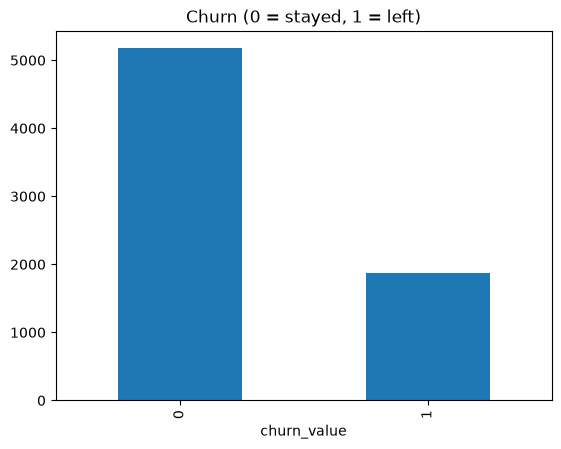

In [8]:
print(df[TARGET].value_counts())
print("Churn rate:", round(df[TARGET].mean(), 3))
df[TARGET].value_counts().plot(kind="bar", title="Churn (0 = stayed, 1 = left)")
plt.show()

### 1. Target balance

- 5,174 stayed (0), 1,869 churned (1). **Churn rate = 26.5%.**
- The classes are **imbalanced** (about 1 churner in 4). A model that always predicts "stays" would score 73.5% accuracy and catch zero churners.

**Implications:** use **PR-AUC** (random baseline = 0.265) instead of accuracy, and **stratified** train/test splits and CV folds.

In [9]:
def churn_rate_by(col):
    return (df.groupby(col)[TARGET]
              .agg(churn_rate="mean", customers="size")
              .sort_values("churn_rate", ascending=False)
              .round(3))

for col in ["contract", "internet_service", "payment_method",
            "tech_support", "online_security", "senior_citizen", "dependents"]:
    print(churn_rate_by(col), "\n")


                churn_rate  customers
contract                             
Month-to-month       0.427       3875
One year             0.113       1473
Two year             0.028       1695 

                  churn_rate  customers
internet_service                       
Fiber optic            0.419       3096
DSL                    0.190       2421
No                     0.074       1526 

                           churn_rate  customers
payment_method                                  
Electronic check                0.453       2365
Mailed check                    0.191       1612
Bank transfer (automatic)       0.167       1544
Credit card (automatic)         0.152       1522 

                     churn_rate  customers
tech_support                              
No                        0.416       3473
Yes                       0.152       2044
No internet service       0.074       1526 

                     churn_rate  customers
online_security                           
No     

### 2. Churn rate by segment

| Segment | Highest churn | Lowest churn |
|---|---|---|
| Contract | Month-to-month **42.7%** | Two year **2.8%** (15× lower) |
| Internet service | Fiber optic **41.9%** | No internet 7.4% |
| Payment method | Electronic check **45.3%** | Automatic methods ~15–17% |
| Tech support | No support **41.6%** | With support 15.2% |
| Online security | No security **41.8%** | With security 14.6% |
| Senior citizen | Seniors **41.7%** | Non-seniors 23.6% |
| Dependents | No dependents **32.6%** | With dependents **6.5%** |

- **Contract type is the strongest single driver.** Long contracts lock customers in.
- Customers **without protective add-ons** (tech support, online security) churn ~3× more.
- **Surprise:** dependents has a much stronger effect (6.5% vs 32.6%) than expected.
- All groups are large (1,000+ customers), so these rates are reliable.

**Feature ideas:** count of add-on services, an "automatic payment" flag, and a "has family" flag (partner or dependents).

             tenure_months  monthly_charges  total_charges
churn_value                                               
0                     38.0           64.425       1679.525
1                     10.0           79.650        703.550


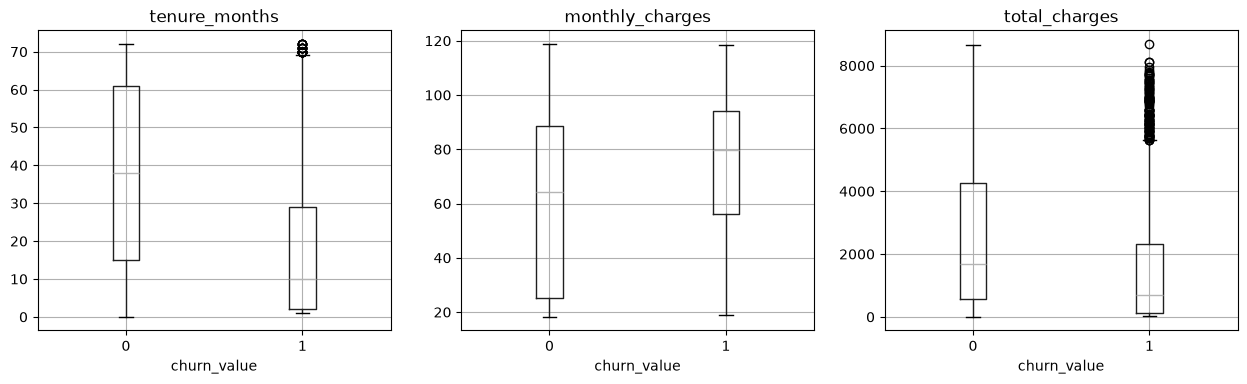

In [10]:
num_cols = ["tenure_months", "monthly_charges", "total_charges"]
print(df.groupby(TARGET)[num_cols].median())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    df.boxplot(column=col, by=TARGET, ax=ax)
    ax.set_title(col)
plt.suptitle("")
plt.show()


### 3. Numeric features: churners vs stayers (medians)

| | Tenure (months) | Monthly charges | Total charges |
|---|---|---|---|
| Stayed | 38 | \$64.43 | \$1,679.53 |
| Churned | **10** | **\$79.65** | \$703.55 |

- **Churners are newer customers who pay more per month.**
- Lower total charges for churners follows from their short tenure, not from spending less per month.
- Medians are used because `total_charges` is right-skewed: many new customers have small totals.

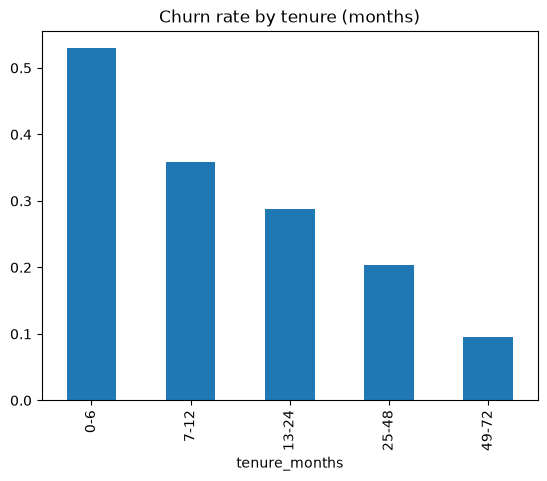

tenure_months
0-6      0.529
7-12     0.359
13-24    0.287
25-48    0.204
49-72    0.095
Name: churn_value, dtype: float64

In [11]:
buckets = pd.cut(df["tenure_months"], bins=[-1, 6, 12, 24, 48, 72],
                 labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
rate = df.groupby(buckets, observed=True)[TARGET].mean()
rate.plot(kind="bar", title="Churn rate by tenure (months)")
plt.show()
rate.round(3)

### 4. Churn rate by tenure

| Tenure (months) | 0–6 | 7–12 | 13–24 | 25–48 | 49–72 |
|---|---|---|---|---|---|
| Churn rate | **52.9%** | 35.9% | 28.7% | 20.4% | 9.5% |

- Risk falls steadily with tenure. **More than half of customers in their first 6 months churn.**
- The first months (onboarding) are where retention effort can pay off most.

**Feature idea:** an `is_new_customer` flag (tenure ≤ 6 months).

In [12]:
df[num_cols + [TARGET]].corr().round(2)

,tenure_months,monthly_charges,total_charges,churn_value
tenure_months,1.00,0.25,0.83,-0.35
monthly_charges,0.25,1.00,0.65,0.19
total_charges,0.83,0.65,1.00,-0.20
churn_value,-0.35,0.19,-0.20,1.00


### 5. Correlations (numeric features + target)

- `tenure_months` ↔ `total_charges` = **0.83**: strongly related, because total ≈ tenure × monthly charge. This is **multicollinearity**, which is fine for tree models but makes logistic-regression coefficients harder to interpret.
- `monthly_charges` ↔ `total_charges` = 0.65.
- Correlation with churn: tenure **−0.35** (longer tenure → less churn), monthly charges +0.19, total charges −0.20.

**Feature idea:** `avg_monthly_spend = total_charges / tenure_months` (use `monthly_charges` when tenure is 0) and the gap to the current monthly charge, to capture price increases.

## Summary

**Key findings**
1. Churn rate is **26.5%**: imbalanced, so use PR-AUC and stratified splits.
2. **Contract** is the strongest driver: month-to-month 42.7% vs two-year 2.8%.
3. **Tenure**: 52.9% churn in the first 6 months vs 9.5% after 4 years. Churners' median tenure is 10 months vs 38.
4. **Fiber optic**, **electronic check** payment, and **no tech support / online security** each roughly double to triple churn.
5. **Seniors** and customers **without dependents** churn more. The dependents effect (6.5% vs 32.6%) was a surprise.
6. `tenure_months` and `total_charges` are highly correlated (0.83).

**Hypotheses from `docs/problem_framing.md`:** all confirmed (month-to-month ~43%, two-year ~3%, fiber ~42%, electronic check ~45%, short tenure and missing support add-ons drive churn).

**Next steps (feature engineering and modeling)**
- Engineered features to test: `is_new_customer`, `num_addon_services`, `has_auto_payment`, `has_family`, `avg_monthly_spend`, `charge_increase`.
- A rule baseline to beat: "flag every month-to-month customer".
- Compare logistic regression and LightGBM with stratified 5-fold CV on PR-AUC.

**Caution:** these are associations, not causes. For example, moving customers to automatic payment would not necessarily keep them. Proving that an action reduces churn needs an A/B test.